# Results: parameter counts, training curves, test accuracy

Everything here runs on CPU in under a minute from files in this repository:

| Evidence | Source |
|---|---|
| Parameter counts | models built from `a_resnet_scaling/` and `b_width_depth/` code |
| Training / validation curves (A) | `results/a_logs/*/history.json`, written by the training scripts |
| Checkpoint and TTA selection (A) | `results/a_logs/*/inference_comparison.json`, `results/a_selection/` |
| Submitted B checkpoints | `results/b_checkpoints.json` (epoch, raw/EMA, parameters and SHA-256 of each `.pt`) |
| Submitted B predictions | `results/b_submissions/*.csv` |
| Test accuracy | `results/leaderboard.csv`: recorded public / private leaderboard scores |

Test labels are hidden, so test accuracy is the recorded leaderboard score. Everything else is recomputed below from the archived files. No model is retrained or re-evaluated here.

In [1]:
import csv, importlib.util, json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'results'
FIGURES = RESULTS / 'figures'; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

def load_module(path, name):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module); return module

sys.path.insert(0, str(ROOT / 'a_resnet_scaling'))
import wide_resnet                                            # builds both A0/A1 ResNets and A2/A3 WRN
b_models = load_module(ROOT / 'b_width_depth/models/resnet.py', 'b_models')
a_config = lambda name: json.loads((ROOT / 'a_resnet_scaling/configs' / f'{name}.json').read_text())
count_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
print('torch', torch.__version__)

torch 2.15.0+cu132


## 1 · Parameter counts (limit: 5,000,000)

In [2]:
architectures = {
    'A0':       wide_resnet.build_model(a_config('a0_resnet18_baseline')),
    'A1':       wide_resnet.build_model(a_config('a1_full_mixing')),
    'A2, A3':   wide_resnet.build_model(a_config('a2_full_wrn')),
    'B1, B4, B5': b_models.WideResNet(widths=(56, 112, 224), blocks_per_stage=(4, 4, 4)),
    'B2':       b_models.WideResNet(widths=(80, 160, 320), blocks_per_stage=(2, 2, 2)),
    'B3, B6, B7': b_models.WideResNet(widths=(64, 128, 256), blocks_per_stage=(4, 4, 3)),
}
param_counts = {}
for ids, model in architectures.items():
    n = count_params(model)
    param_counts[ids] = n
    assert n <= 5_000_000
    print(f'{ids:<11} {model.__class__.__name__:<22} {n:>10,} trainable parameters   ({n / 5e6:.1%} of budget)')

A0          CifarResNet             2,797,610 trainable parameters   (56.0% of budget)
A1          CifarResNet             4,368,690 trainable parameters   (87.4% of budget)
A2, A3      WideResNet              4,480,474 trainable parameters   (89.6% of budget)
B1, B4, B5  WideResNet              4,500,898 trainable parameters   (90.0% of budget)
B2          WideResNet              4,336,410 trainable parameters   (86.7% of budget)
B3, B6, B7  WideResNet              4,696,394 trainable parameters   (93.9% of budget)


Forward-pass check: every architecture maps a CIFAR batch to 10 logits.

In [3]:
x = torch.randn(2, 3, 32, 32)
for ids, model in architectures.items():
    model.eval()
    with torch.no_grad():
        print(f'{ids:<11} output shape {tuple(model(x).shape)}')

A0          output shape (2, 10)
A1          output shape (2, 10)
A2, A3      output shape (2, 10)
B1, B4, B5  output shape (2, 10)
B2          output shape (2, 10)
B3, B6, B7  output shape (2, 10)


## 2 · Final test accuracy (recorded leaderboard scores)

In [4]:
board = list(csv.DictReader((RESULTS / 'leaderboard.csv').open()))
print(f"{'ID':<4} {'Params':>10} {'Val %':>6} {'Public %':>9} {'Private %':>10}  Model")
for r in board:
    print(f"{r['id']:<4} {int(r['parameters']):>10,} {r['validation_percent'] or '-':>6} "
          f"{float(r['public_percent_recorded']):>9.1f} {float(r['private_percent_recorded']):>10.1f}  {r['model']}")

best = max(board, key=lambda r: float(r['private_percent_recorded']))
print()
print(f"FINAL MODEL: {best['id']} - {best['model']}")
print(f"  trainable parameters : {int(best['parameters']):,}")
print(f"  test accuracy        : {best['private_percent_recorded']}% (private leaderboard, recorded), {best['public_percent_recorded']}% (public leaderboard, recorded)")

ID       Params  Val %  Public %  Private %  Model
A0    2,797,610  94.54      82.5       80.0  ResNet-18 style 32-256, crop/flip, 100 ep
A1    4,368,690  96.44      85.9       84.1  Wider ResNet 40-320, Mixup/CutMix, 200 ep (all data)
A2    4,480,474  97.30      88.3       85.3  WRN 56/112/224 x4, RandAugment + Cutout, EMA, BN recalibration, 300 ep (all data)
A3    4,480,474  97.58      88.6       86.2  A2 + 80 SAM epochs (all data)
B1    4,500,898      -      88.4       86.3  Deep/narrow WRN 56/112/224 x(4,4,4), 300 ep (all data)
B2    4,336,410      -      88.7       85.4  Wide/shallow WRN 80/160/320 x(2,2,2), 300 ep (all data)
B3    4,696,394  96.82      88.9       84.1  Larger WRN 64/128/256 x(4,4,3) + RandomErasing, fold 0
B4    4,500,898  96.90      88.5       85.4  Deep/narrow, RandAugment M=7, CutMix 0.75, LS 0.1, fold 0
B5    4,500,898      -      87.9       86.0  B4 recipe, separate run (file name indicates fold 1)
B6    4,696,394      -      88.8       84.2  B3 recipe, sepa

## 3 · Pipeline A training curves

Development runs (45k train / 5k validation). Train accuracy is measured on augmented batches; with Mixup/CutMix (A1)
it is the label-weighted accuracy, so it sits below validation accuracy. A3 continues A2's final EMA weights for 80 epochs.

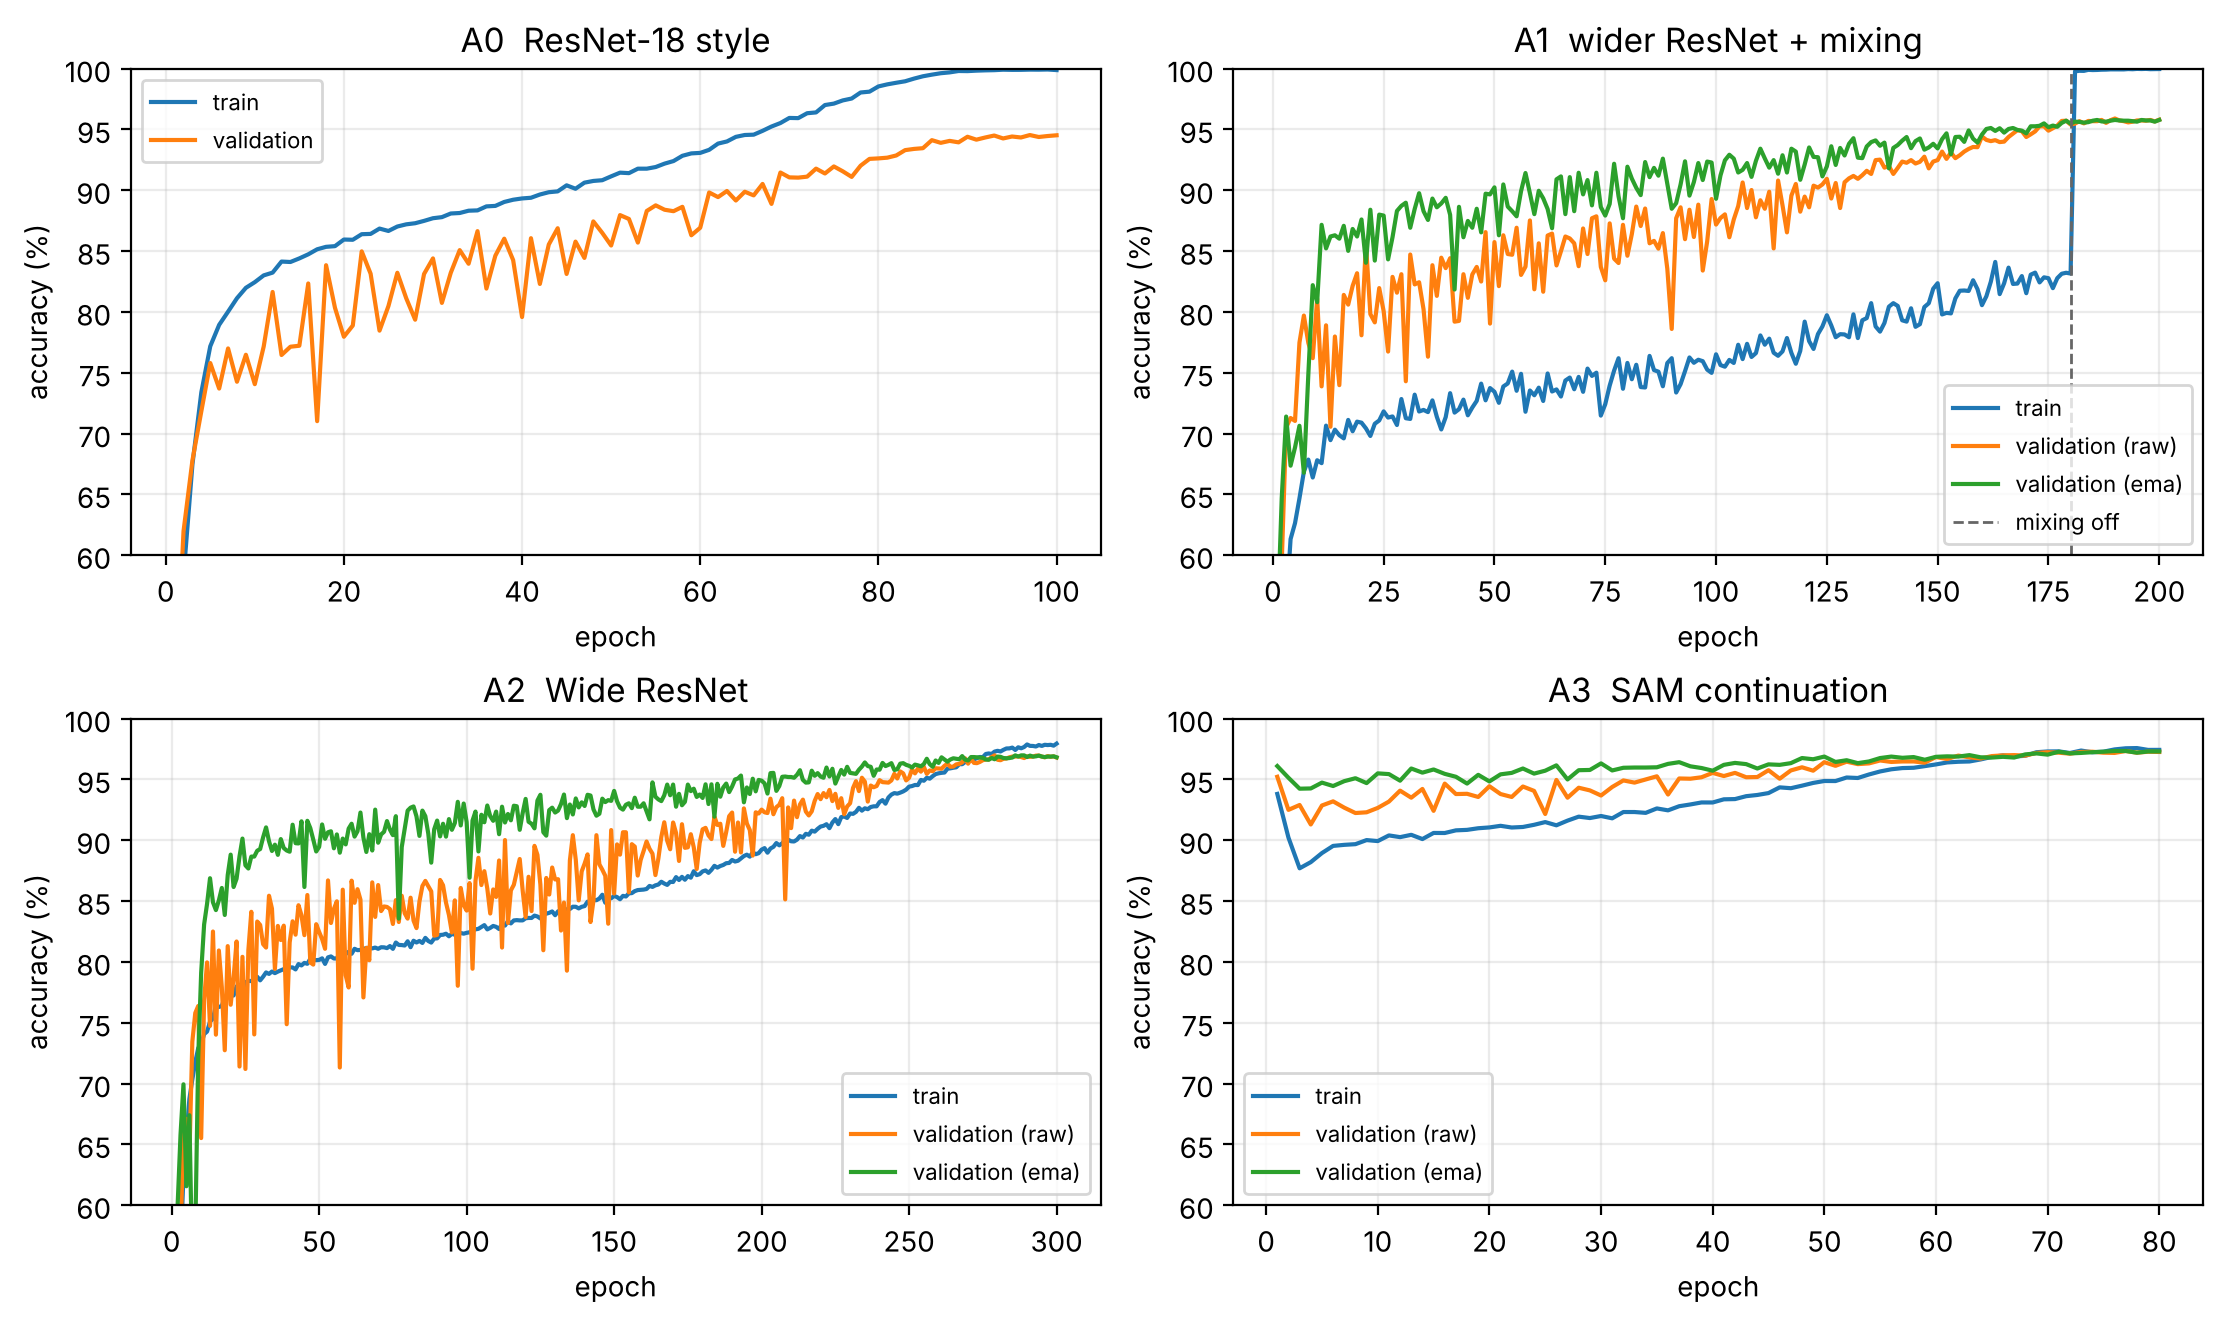

In [5]:
RUNS = [('a0_baseline', 'A0  ResNet-18 style'), ('a1_dev_mixing', 'A1  wider ResNet + mixing'),
        ('a2_dev_wrn', 'A2  Wide ResNet'), ('a3_dev_sam', 'A3  SAM continuation')]
history = {run: json.loads((RESULTS / 'a_logs' / run / 'history.json').read_text()) for run, _ in RUNS}

def series(rows, *keys):
    for key in keys:
        if key in rows[0]:
            return [r[key] for r in rows]

def plot_curves(metric, ylabel, filename):
    fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), layout='constrained')
    for ax, (run, title) in zip(axes.flat, RUNS):
        rows = history[run]; epochs = [r['epoch'] for r in rows]
        ax.plot(epochs, series(rows, f'train_{metric}', 'train_weighted_accuracy'), label='train')
        if f'val_{metric}' in rows[0]:
            ax.plot(epochs, series(rows, f'val_{metric}'), label='validation')
        for variant in ('raw', 'ema'):
            if f'{variant}_val_{metric}' in rows[0]:
                ax.plot(epochs, series(rows, f'{variant}_val_{metric}'), label=f'validation ({variant})')
        if run == 'a1_dev_mixing':
            ax.axvline(180, color='0.4', ls='--', lw=1, label='mixing off')
        if metric == 'accuracy':
            ax.set_ylim(60, 100)
        ax.set(title=title, xlabel='epoch', ylabel=ylabel); ax.legend(fontsize=8)
    fig.savefig(FIGURES / filename, dpi=150); plt.show()

plot_curves('accuracy', 'accuracy (%)', 'a_accuracy.png')

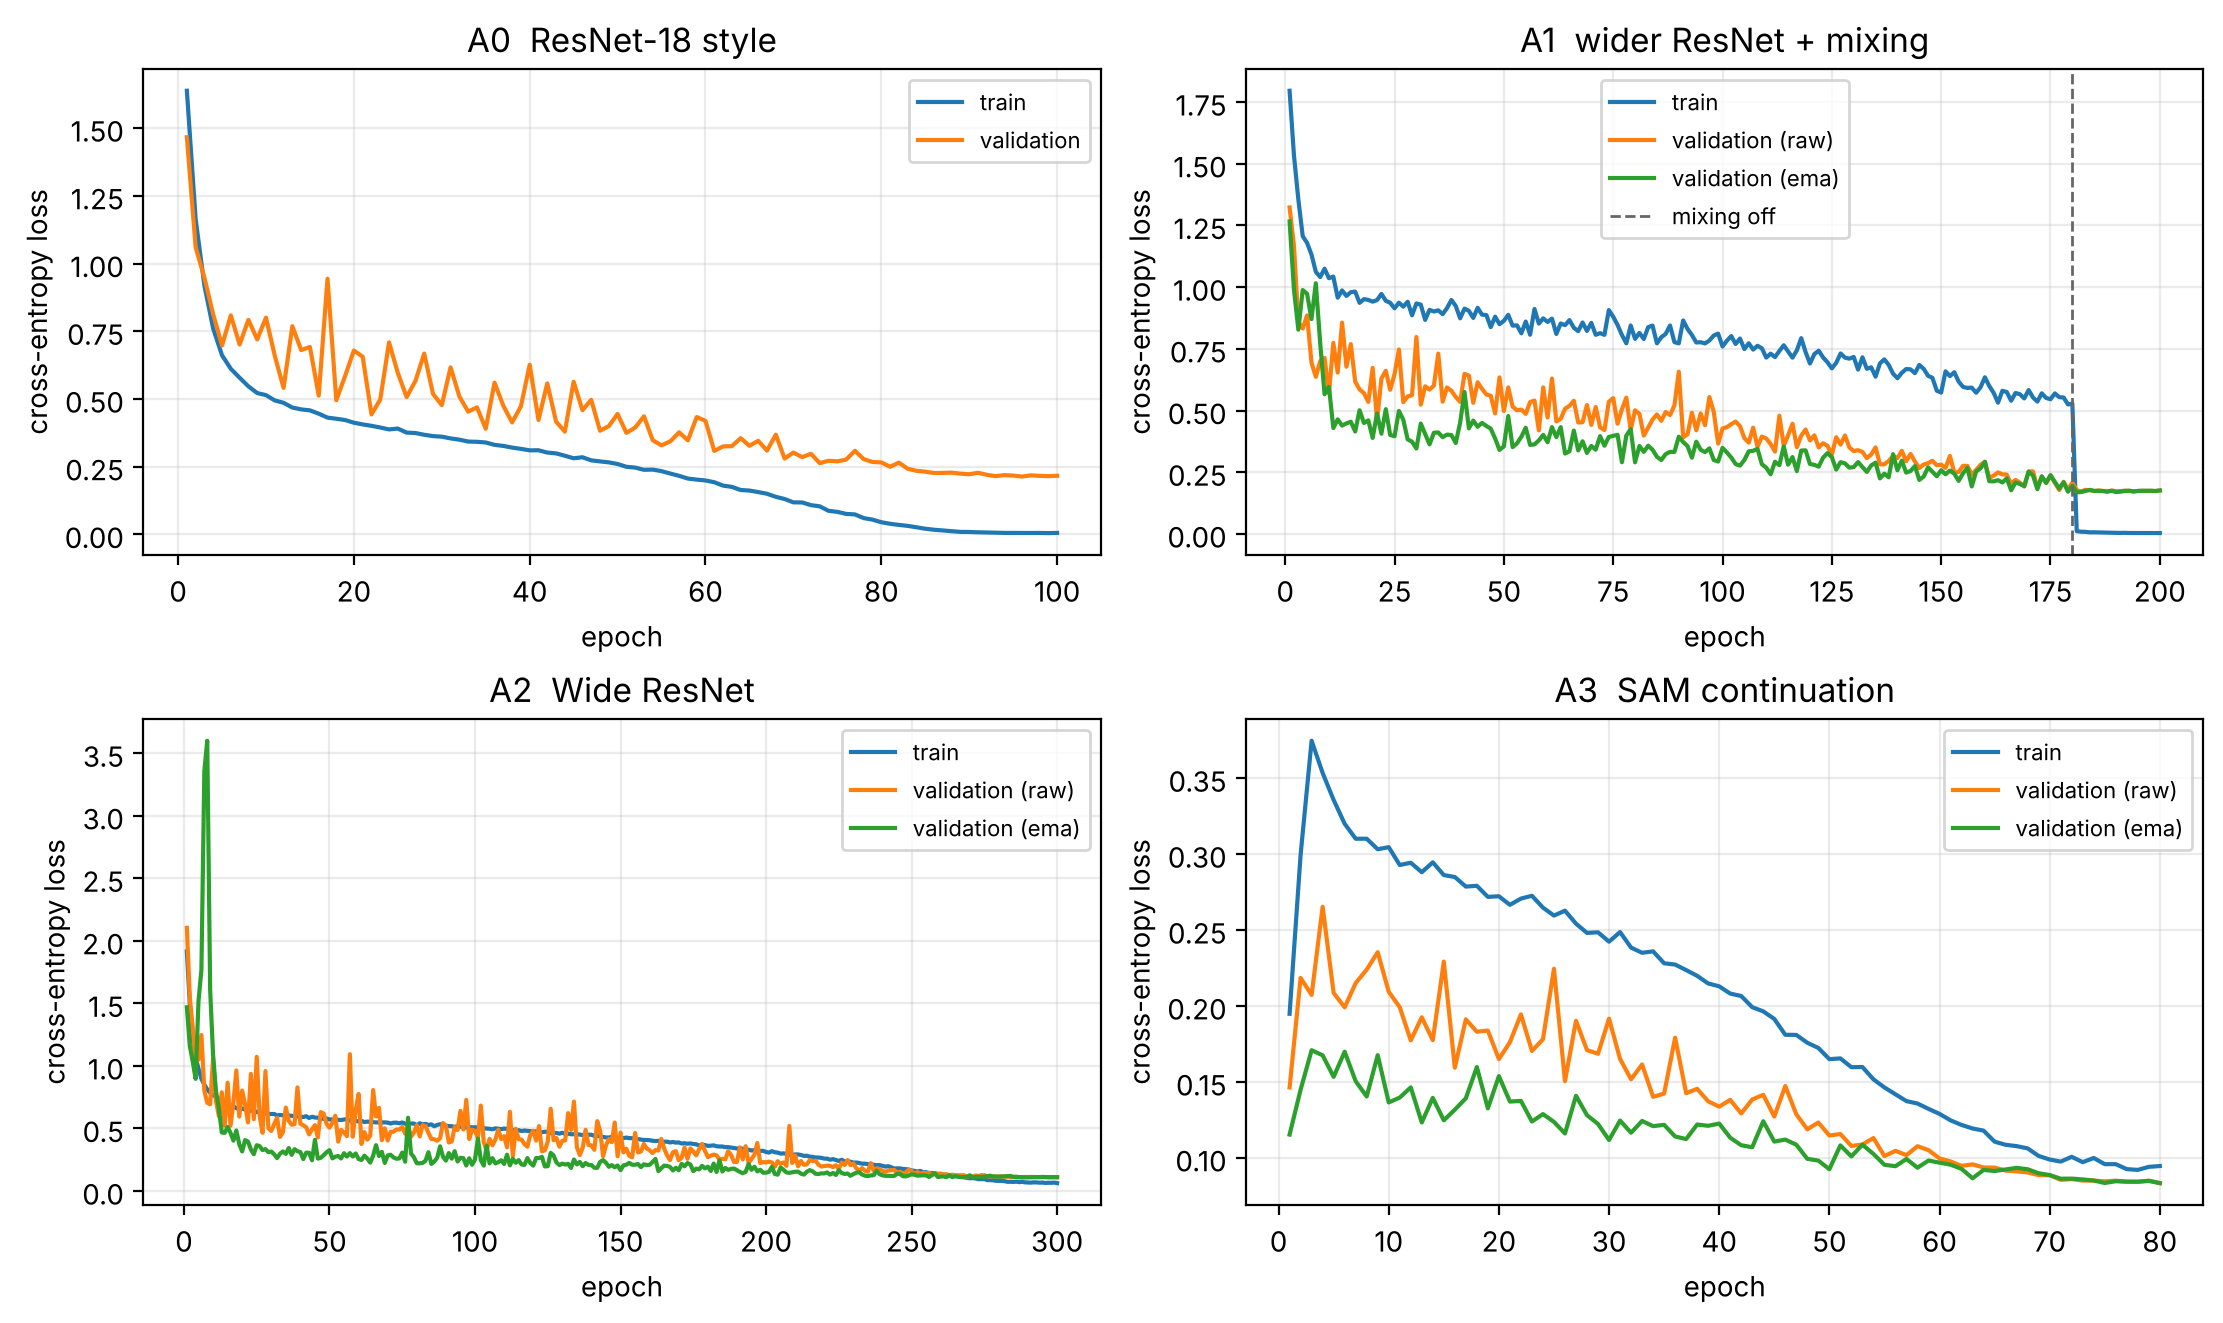

In [6]:
plot_curves('loss', 'cross-entropy loss', 'a_loss.png')

In [7]:
print(f"{'run':<16} {'epochs':>6} {'best val %':>10} {'at epoch':>8} {'weights':>8} {'train time (min)':>17}")
for run, _ in RUNS:
    s = json.loads((RESULTS / 'a_logs' / run / 'summary.json').read_text())
    b = s.get('best_validation') or {'accuracy': s['best_validation_accuracy'], 'epoch': s['best_epoch']}
    print(f"{run:<16} {s['completed_epochs']:>6} {b['accuracy']:>10.2f} {b['epoch']:>8} {b.get('variant', 'raw'):>8} "
          f"{s['training_seconds'] / 60:>17.1f}")
print('(best validation without test-time augmentation; selected checkpoints below use flip TTA)')

run              epochs best val % at epoch  weights  train time (min)
a0_baseline         100      94.54       97      raw               6.7
a1_dev_mixing       200      95.90      190      raw              13.9
a2_dev_wrn          300      96.98      289      ema              52.9
a3_dev_sam           80      97.34       77      ema              65.1
(best validation without test-time augmentation; selected checkpoints below use flip TTA)


All-data refits (50k images, no validation set): training loss of the submitted runs.

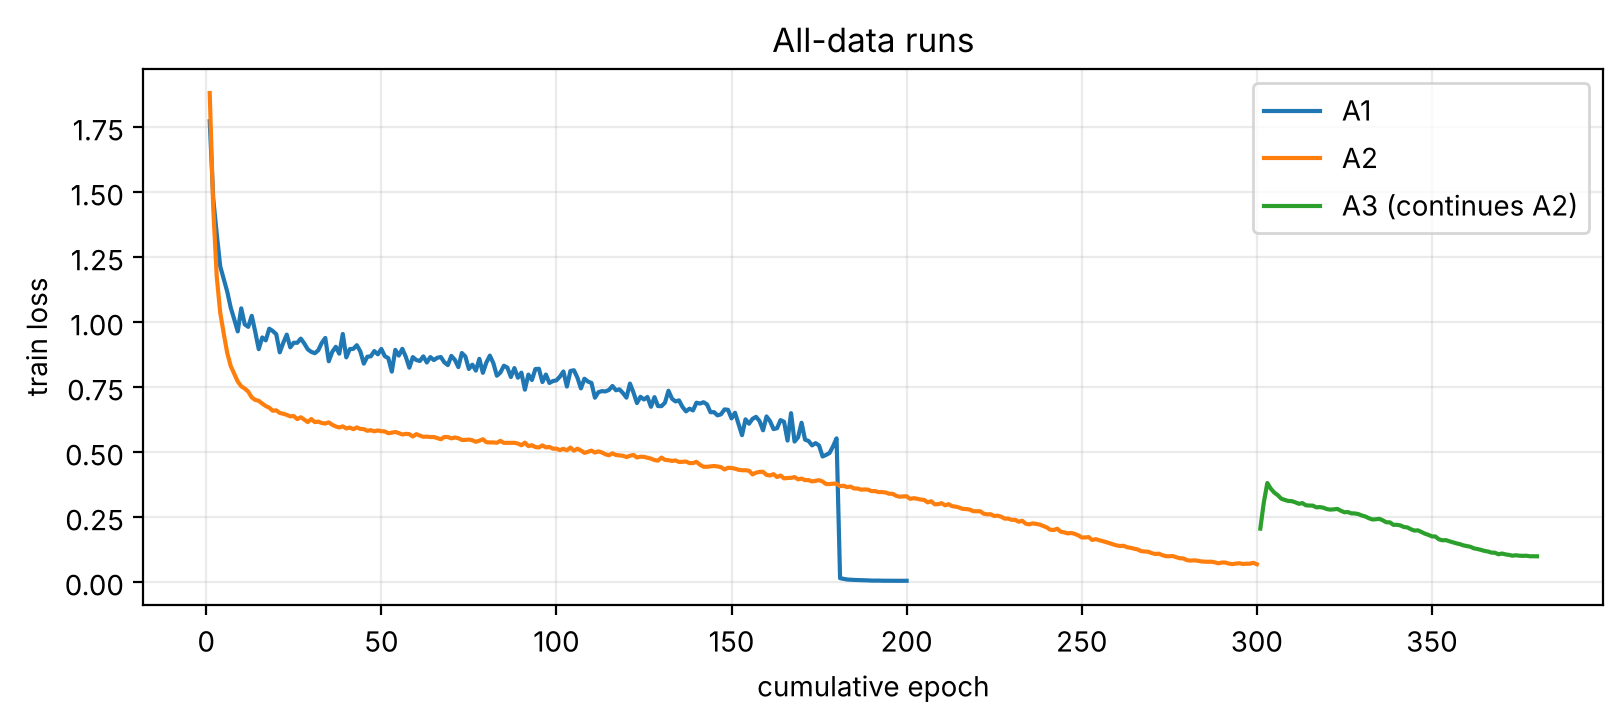

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
for run, label in [('a1_full_mixing', 'A1'), ('a2_full_wrn', 'A2'), ('a3_full_sam', 'A3 (continues A2)')]:
    rows = json.loads((RESULTS / 'a_logs' / run / 'history.json').read_text())
    offset = 300 if run == 'a3_full_sam' else 0
    ax.plot([r['epoch'] + offset for r in rows], [r['train_loss'] for r in rows], label=label)
ax.set(xlabel='cumulative epoch', ylabel='train loss', title='All-data runs'); ax.legend()
fig.savefig(FIGURES / 'a_full_data_loss.png', dpi=150); plt.show()

## 4 · Pipeline A checkpoint and test-time-augmentation selection (validation, 5,000 images)

In [9]:
for step in ('a1', 'a2', 'a3'):
    sel = json.loads((RESULTS / 'a_selection' / f'{step}.json').read_text())
    name = lambda c: c.get('checkpoint') or f"runs/{c['run']}/best.pt"
    print(f"{step.upper()}: selected {name(sel)}  policy={sel['policy']}  val={sel['validation_accuracy']:.2f}%")
    for c in sel.get('candidates', []):
        mark = '*' if name(c) == name(sel) else ' '
        print(f"   {mark} {name(c):<48} epoch {c['checkpoint_epoch']:>3}  {c['variant']:<3}  "
              f"BN-recal={str(c.get('recalibrate_bn', False)):<5}  {c['validation_accuracy']:.2f}%")
    print()

A1: selected runs/a1_dev_mixing/best.pt  policy=flip  val=96.44%
     runs/a1_dev_cutout/best.pt                       epoch 189  ema  BN-recal=False  96.24%
   * runs/a1_dev_mixing/best.pt                       epoch 190  raw  BN-recal=False  96.44%

A2: selected runs/a2_dev_wrn/final_ema/calibrated/best.pt  policy=flip  val=97.30%
     runs/a2_dev_wrn/best.pt                          epoch 289  ema  BN-recal=False  97.26%
     runs/a2_dev_wrn/calibrated/best.pt               epoch 289  ema  BN-recal=True   97.20%
     runs/a2_dev_wrn/final_raw/best.pt                epoch 300  raw  BN-recal=False  97.22%
     runs/a2_dev_wrn/final_raw/calibrated/best.pt     epoch 300  raw  BN-recal=True   97.30%
     runs/a2_dev_wrn/final_ema/best.pt                epoch 300  ema  BN-recal=False  97.20%
   * runs/a2_dev_wrn/final_ema/calibrated/best.pt     epoch 300  ema  BN-recal=True   97.30%

A3: selected runs/a3_dev_sam/final_ema/best.pt  policy=flip  val=97.58%
     runs/a3_dev_sam/best.pt      

In [10]:
print('TTA policies on the selected development checkpoints:')
for path in ['a1_dev_mixing/inference_comparison.json', 'a2_dev_wrn/final_ema/calibrated/inference_comparison.json',
             'a3_dev_sam/final_ema/inference_comparison.json']:
    d = json.loads((RESULTS / 'a_logs' / path).read_text())
    print(f"  {path.split('/')[0]:<14}", '  '.join(f"{p}={v['accuracy']:.2f}%" for p, v in d['policies'].items()))

TTA policies on the selected development checkpoints:
  a1_dev_mixing  none=95.90%  flip=96.44%  shift_flip=95.94%
  a2_dev_wrn     none=96.86%  flip=97.30%  shift_flip=97.12%
  a3_dev_sam     none=97.30%  flip=97.58%  shift_flip=97.30%  scale_flip=97.16%  crop36=96.64%


## 5 · Robustness probe (A): validation accuracy under synthetic degradations

In [11]:
probe = [('A3', 'a3_dev_sam/degradation_eval.json'),
         ('A3 + 1 epoch degradation training', 'probe_dev_degradation/degradation_eval.json'),
         ('A3 + 100 epochs degradation training', 'probe_dev_degradation/final_ema/robustness.json')]
conditions = ['clean', 'gaussian_noise_003', 'blur_sigma06', 'downsample24', 'brightness07']
print(f"{'checkpoint':<38}" + ''.join(f'{c:>20}' for c in conditions) + f"{'degraded mean':>15}")
for name, path in probe:
    d = json.loads((RESULTS / 'a_logs' / path).read_text())['conditions']
    acc = [d[c]['accuracy'] for c in conditions]
    print(f'{name:<38}' + ''.join(f'{a:>20.2f}' for a in acc) + f'{np.mean(acc[1:]):>15.2f}')

checkpoint                                           clean  gaussian_noise_003        blur_sigma06        downsample24        brightness07  degraded mean
A3                                                   97.58               92.20               96.46               92.56               97.38          94.65
A3 + 1 epoch degradation training                    97.32               94.94               96.76               95.14               96.88          95.93
A3 + 100 epochs degradation training                 96.88               96.00               96.70               95.90               96.58          96.29


## 6 · Pipeline B: submitted checkpoints and predictions

`b_checkpoints.json` records each submitted weight file: epoch, raw or EMA weights, validation accuracy saved in the
checkpoint, the parameter count read from the weights, and a SHA-256 hash. The counts match the architectures in section 1.

In [12]:
ckpts = json.loads((RESULTS / 'b_checkpoints.json').read_text())
print(f"{'ID':<8} {'file':<9} {'epoch':>5} {'weights':>7} {'val %':>6} {'params':>10}  widths x blocks")
for c in ckpts:
    val = f"{100 * c['val_acc']:.2f}" if c['val_acc'] else '-'
    print(f"{c['id']:<8} {c['checkpoint']:<9} {c['epoch']:>5} {c['weights_source']:>7} {val:>6} "
          f"{c['trainable_parameters']:>10,}  {c['widths']} x {c['blocks_per_stage']}")

ID       file      epoch weights  val %     params  widths x blocks
B1       final.pt    295     raw      -  4,500,898  [56, 112, 224] x [4, 4, 4]
B2       final.pt    298     raw      -  4,336,410  [80, 160, 320] x [2, 2, 2]
B3       best.pt     289     raw  96.82  4,696,394  [64, 128, 256] x [4, 4, 3]
B4       best.pt     297     raw  96.90  4,500,898  [56, 112, 224] x [4, 4, 4]
B3-full  final.pt    294     raw      -  4,696,394  [64, 128, 256] x [4, 4, 3]


All submission files: 2000 rows, labels 0-9.

Predicted class counts:
  B1       [172 214 203 202 199 225 185 195 204 201]
  B2       [177 209 195 213 194 219 180 203 208 202]
  B3       [167 220 217 197 187 217 191 198 208 198]
  B4       [174 216 212 207 193 212 185 198 207 196]
  B3-full  [174 218 206 200 200 211 186 204 204 197]


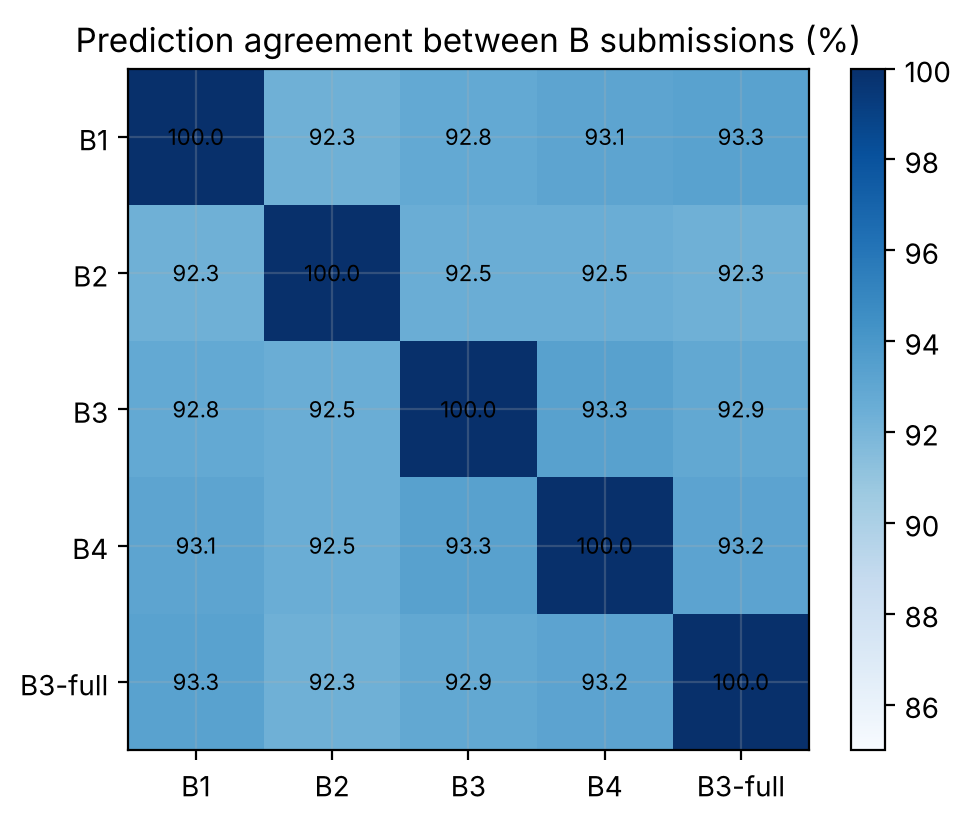

In [13]:
subs = {c['id']: np.array([int(r['label']) for r in csv.DictReader((ROOT / c['submission']).open())]) for c in ckpts}
ids = list(subs)
for i in ids:
    assert len(subs[i]) == 2000 and set(subs[i]) <= set(range(10))
print('All submission files: 2000 rows, labels 0-9.')
print('\nPredicted class counts:')
for i in ids:
    print(f'  {i:<8}', np.bincount(subs[i], minlength=10))
agree = np.array([[np.mean(subs[a] == subs[b]) * 100 for b in ids] for a in ids])
fig, ax = plt.subplots(figsize=(5, 4), layout='constrained')
im = ax.imshow(agree, vmin=85, vmax=100, cmap='Blues')
ax.set_xticks(range(len(ids)), ids); ax.set_yticks(range(len(ids)), ids)
for a in range(len(ids)):
    for b in range(len(ids)):
        ax.text(b, a, f'{agree[a, b]:.1f}', ha='center', va='center', fontsize=8)
ax.set_title('Prediction agreement between B submissions (%)'); fig.colorbar(im)
fig.savefig(FIGURES / 'b_agreement.png', dpi=150); plt.show()

Epoch selection for the B1/B2 all-data refits: `b_width_depth/select_full_data_epoch.py` reads three fold runs'
`history.csv` and prints each fold's best raw-weight epoch and their median. If fold logs are placed in
`results/b_fold_logs/<recipe>/fold{0,1,2}/history.csv`, the next cell runs it.

In [14]:
select = load_module(ROOT / 'b_width_depth/select_full_data_epoch.py', 'select_epoch')
fold_root = RESULTS / 'b_fold_logs'
if fold_root.exists():
    for recipe in sorted(p for p in fold_root.iterdir() if p.is_dir()):
        print(f'== {recipe.name}')
        sys.argv = ['select_full_data_epoch.py', *map(str, sorted(recipe.glob('fold*')))]
        select.main()
else:
    print('No fold logs in results/b_fold_logs/.')

No fold logs in results/b_fold_logs/.


## 7 · Public vs private leaderboard

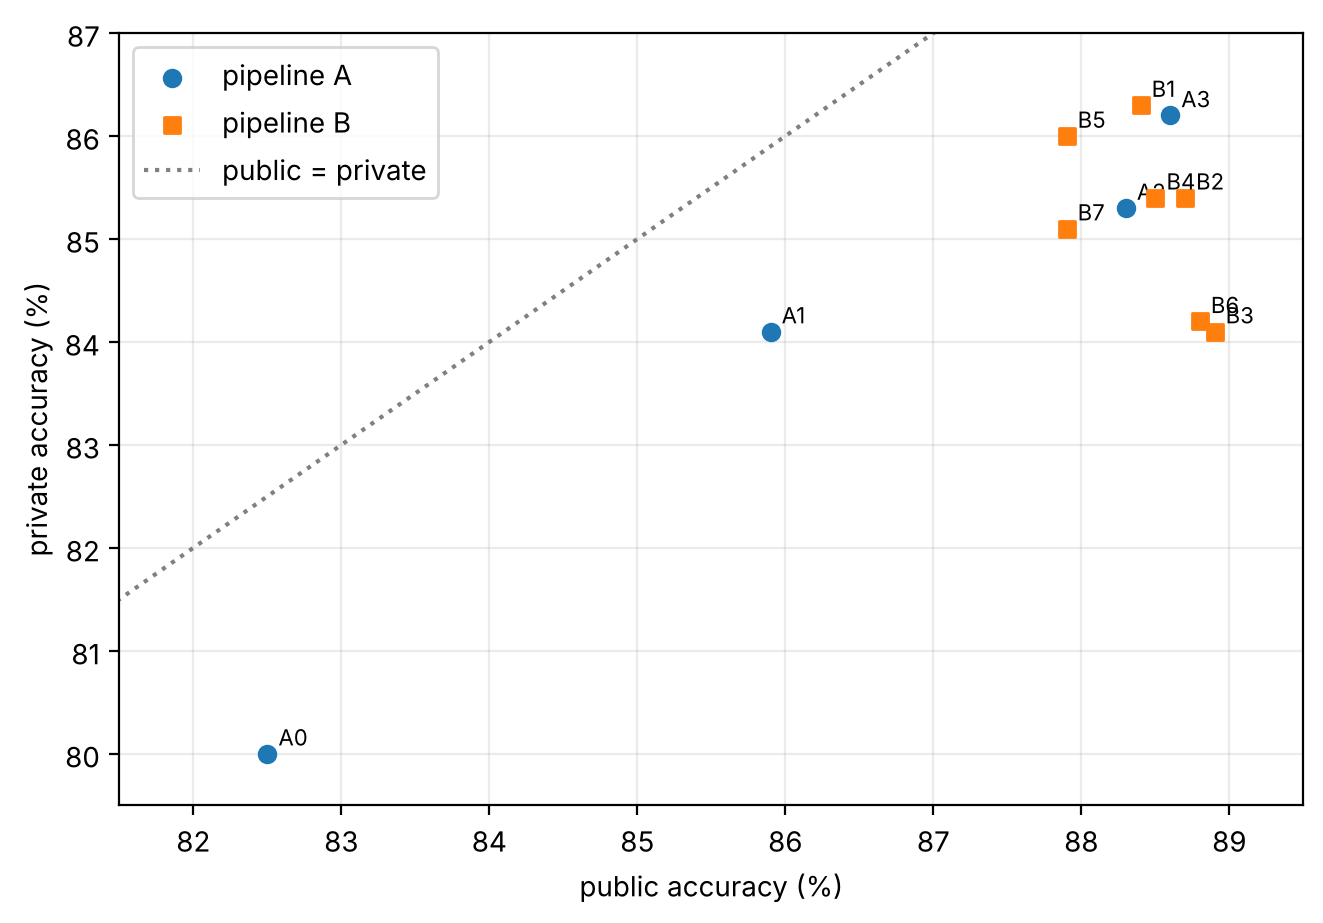

Public-private correlation over 11 submissions: 0.85
Among the 9 submissions with public >= 87.5%: correlation -0.47


In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4.5), layout='constrained')
for track, marker in (('A', 'o'), ('B', 's')):
    rows = [r for r in board if r['id'].startswith(track)]
    ax.scatter([float(r['public_percent_recorded']) for r in rows], [float(r['private_percent_recorded']) for r in rows],
               marker=marker, label=f'pipeline {track}', zorder=3)
    for r in rows:
        ax.annotate(r['id'], (float(r['public_percent_recorded']), float(r['private_percent_recorded'])),
                    xytext=(4, 3), textcoords='offset points', fontsize=8)
ax.plot([80, 90], [80, 90], ':', color='0.5', label='public = private')
ax.set(xlabel='public accuracy (%)', ylabel='private accuracy (%)', xlim=(81.5, 89.5), ylim=(79.5, 87))
ax.legend(); fig.savefig(FIGURES / 'public_private.png', dpi=150); plt.show()
pub = np.array([float(r['public_percent_recorded']) for r in board]); priv = np.array([float(r['private_percent_recorded']) for r in board])
print(f'Public-private correlation over {len(board)} submissions: {np.corrcoef(pub, priv)[0, 1]:.2f}')
top = [r for r in board if float(r['public_percent_recorded']) >= 87.5]
print(f'Among the {len(top)} submissions with public >= 87.5%: correlation '
      f"{np.corrcoef([float(r['public_percent_recorded']) for r in top], [float(r['private_percent_recorded']) for r in top])[0, 1]:.2f}")